In [1]:
import pandas as pd
dataset=pd.read_csv("50_Startups_dataset.csv")

In [2]:
dataset

,Unnamed: 0,R&D Spend,Administration,Marketing Spend,State,Profit
0,0,165349.30,136897.90,471784.20,New York,192261.93
1,1,162597.80,151377.69,443898.63,California,191792.16
2,2,153441.61,101145.65,407934.64,Florida,191050.49
3,3,144372.51,118671.95,383199.72,New York,182902.09
4,4,142107.44,91391.87,366168.52,Florida,166188.04
5,5,131877.00,99814.81,362861.46,New York,156991.22
6,6,134615.56,147198.97,127716.92,California,156122.61
7,7,130298.23,145530.16,323876.78,Florida,155752.70
8,8,120542.62,148719.05,311613.39,New York,152211.87
9,9,123334.98,108679.27,304981.72,California,149760.06


In [3]:
dataset.isnull().sum()

Unnamed: 0         0
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

In [5]:
x = dataset[['R&D Spend','Administration','Marketing Spend']]
y = dataset['Profit']

In [6]:
print(x.head())

   R&D Spend  Administration  Marketing Spend
0  165349.30       136897.90        471784.20
1  162597.80       151377.69        443898.63
2  153441.61       101145.65        407934.64
3  144372.51       118671.95        383199.72
4  142107.44        91391.87        366168.52


In [7]:
y.head()

0    192261.93
1    191792.16
2    191050.49
3    182902.09
4    166188.04
Name: Profit, dtype: float64

In [9]:
print(x.shape)
print(y.shape)

(50, 3)
(50,)


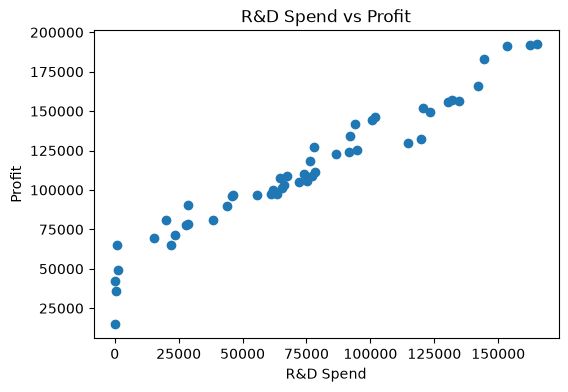

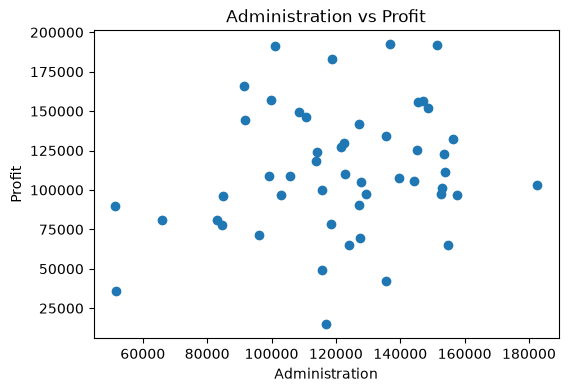

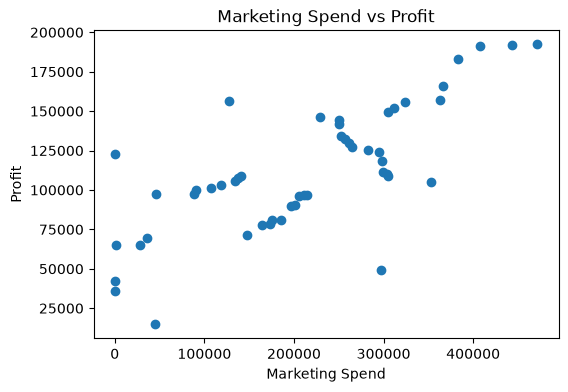

In [10]:
features = ['R&D Spend', 'Administration', 'Marketing Spend']

for col in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(dataset[col], dataset['Profit'])
    plt.xlabel(col)
    plt.ylabel('Profit')
    plt.title(f'{col} vs Profit')
    plt.show()

In [11]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [12]:
x_train

,R&D Spend,Administration,Marketing Spend
12,93863.85,127320.48,249839.54
4,142107.44,91391.87,366168.52
37,44070.05,51283.24,197029.52
8,120542.62,148719.05,311613.39
3,144372.51,118671.95,383199.72
6,134615.56,147198.97,127716.92
41,27893.02,84710.87,164470.81
46,1315.56,115816.31,297114.56
47,0.10,135427.02,0.10
15,114523.71,122616.94,261776.33


In [13]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.8 ,-0.07, 0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['R&D Spend','Administration','Marketing Spend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.407e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [14]:
y_pred=regressor.predict(x_test)
y_pred

array([126703.12716461,  84894.85081556,  98893.51815974,  46501.80815036,
       129128.49734381,  50992.79486261, 109016.6536578 , 100878.5641454 ,
        97700.69638629, 113106.25292226])

In [15]:
from sklearn.metrics import r2_score
result=r2_score(y_test,y_pred)
result

0.9000653083037321

In [17]:
profit = regressor.predict([[100000, 120000, 200000]])
profit

C:\Users\aashi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([132546.63489917])

In [18]:
import pickle
filename="ml_model2.sav"
pickle.dump(regressor,open(filename,"wb"))


In [19]:
import pickle
model=pickle.load(open("ml_model2.sav","rb"))

In [20]:
result=model.predict([[100000, 120000, 200000]])
result

C:\Users\aashi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([132546.63489917])

In [21]:
rd_spend = float(input("Enter R&D Spend: "))
admin_spend = float(input("Enter Administration Spend: "))
marketing_spend = float(input("Enter Marketing Spend: "))

result = model.predict([[rd_spend, admin_spend, marketing_spend]])

print("Predicted Profit:", result[0])

Enter R&D Spend:  61136.48
Enter Administration Spend:  152702.02
Enter Marketing Spend:  88218.33


Predicted Profit: 95595.28956453479


C:\Users\aashi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
